# Supplementary panel: relative clone size of fast- vs slow-maturing monocyte metaclones (Weinreb)

Supports the V6 Results sentence "Fast- and slow-maturing clones also differed in how their size changed over time".
Sequenced cells per clone at Days 2, 4 and 6 for the slow-maturing (MC6, MC8) and fast-maturing (MC7, MC12) monocyte-output
metaclones. Because all clones were sampled in the same way, the counts reflect relative rather than absolute clone size.

**Environment:** micromamba env `chronoclone`, path `/path/to/ChronoClone/.runtime/chronoclone`, kernel `chronoclone`.
**Execution:** `/path/to/ChronoClone/.runtime/chronoclone/bin/jupyter nbconvert --to notebook --execute --inplace --ExecutePreprocessor.kernel_name=chronoclone 0001_fast_slow_clone_size_panel.ipynb`

Input (read-only): `ChronoClone_paper/analysis/weinreb/tables/ancestry/ancestry_all_clone_day_linkage.csv` (one row per clone and day; 0 = clone not recovered that day).
Colours follow Figure 3C–D (blue = slower-maturing, red = faster-maturing). Only clones recovered on a day are plotted; boxes with unrecovered clones are labelled recovered/total. P values (two-sided Mann–Whitney, fast vs slow) include unrecovered clones as 0, matching the Results text.

In [1]:
import sys, platform
from pathlib import Path
import numpy as np, pandas as pd, scipy, matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker
from scipy.stats import mannwhitneyu
print('python', sys.version.split()[0], '| pandas', pd.__version__, '| numpy', np.__version__, '| scipy', scipy.__version__,
      '| matplotlib', matplotlib.__version__, '|', platform.platform())
LINK = Path('/path/to/ChronoClone/ChronoClone_paper/analysis/weinreb/tables/ancestry/ancestry_all_clone_day_linkage.csv')
OUT = Path.cwd() / 'figures'; OUT.mkdir(exist_ok=True)
TAB = Path.cwd() / 'tables'; TAB.mkdir(exist_ok=True)
matplotlib.rcParams.update({'svg.fonttype': 'none', 'font.family': 'Arial', 'font.size': 7})

python 3.11.15 | pandas 2.3.3 | numpy 2.4.6 | scipy 1.17.1 | matplotlib 3.11.0 | macOS-26.6.2-arm64-arm-64bit


## Panel: sequenced cells per clone by day

,day,n_fast,n_slow,median_fast,median_slow,mannwhitney_p
0,2,64,71,1.0,1.0,0.2142
1,4,64,71,4.0,3.0,0.0045
2,6,64,71,1.0,7.0,0.0000


,day,metaclone,n_clones,median,q25,q75,recovered
0,2,6,33,1.0,1.0,1.00,1.00
1,2,7,23,1.0,1.0,2.00,1.00
2,2,8,38,1.0,1.0,2.00,1.00
3,2,12,41,1.0,1.0,2.00,1.00
4,4,6,33,4.0,2.0,5.00,1.00
5,4,7,23,4.0,2.0,5.00,1.00
6,4,8,38,2.0,1.0,4.00,1.00
7,4,12,41,5.0,2.0,10.00,1.00
8,6,6,33,9.0,3.0,15.00,1.00
9,6,7,23,0.0,0.0,0.00,0.09


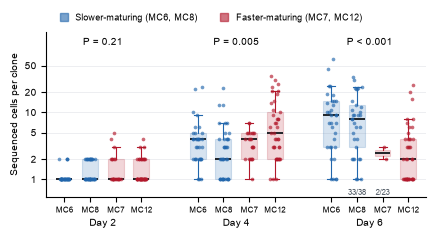

In [2]:
# --- data for this panel ---
SLOW, FAST = [6, 8], [7, 12]
ORDER = SLOW + FAST
COLOR = {'slow': '#2166ac', 'fast': '#b2182b'}
link = pd.read_csv(LINK)
assert link.LARRY_ID.nunique() == 569 and set(link.day) == {2, 4, 6}
d = link[link.metaclone.isin(ORDER)].copy()
d['group'] = np.where(d.metaclone.isin(FAST), 'fast', 'slow')
stats = []
for day in (2, 4, 6):
    f = d[(d.day == day) & (d.group == 'fast')].n_cells
    s = d[(d.day == day) & (d.group == 'slow')].n_cells
    stats.append(dict(day=day, n_fast=len(f), n_slow=len(s), median_fast=f.median(), median_slow=s.median(),
                      mannwhitney_p=mannwhitneyu(f, s, alternative='two-sided').pvalue))
stats = pd.DataFrame(stats)
summary = d.groupby(['day', 'metaclone']).n_cells.agg(n_clones='size', median='median', q25=lambda x: x.quantile(.25),
                                                       q75=lambda x: x.quantile(.75), recovered=lambda x: (x > 0).mean()).reset_index()
stats.to_csv(TAB / 'fast_slow_clone_size_tests.csv', index=False)
summary.to_csv(TAB / 'fast_slow_clone_size_by_metaclone_day.csv', index=False)
display(stats.round(4)); display(summary.round(2))

# --- figure ---
rng = np.random.default_rng(20261113)
fig, ax = plt.subplots(figsize=(4.9, 2.5))
width, gap = 0.62, 1.2
xticks, xlabels = [], []
for k, day in enumerate((2, 4, 6)):
    base = k * (len(ORDER) + gap)
    for j, mc in enumerate(ORDER):
        x = base + j
        g = 'fast' if mc in FAST else 'slow'
        allv = d[(d.day == day) & (d.metaclone == mc)].n_cells.to_numpy()
        v = allv[allv > 0]  # only clones recovered on that day are plotted (The authors: "Don't plot 0")
        ax.boxplot(v, positions=[x], widths=width, whis=1.5, showfliers=False, patch_artist=True,
                   boxprops=dict(facecolor=COLOR[g], alpha=0.18, edgecolor=COLOR[g], linewidth=0.8),
                   whiskerprops=dict(color=COLOR[g], linewidth=0.8), capprops=dict(color=COLOR[g], linewidth=0.8),
                   medianprops=dict(color='#1f2328', linewidth=1.4))
        ax.scatter(x + rng.uniform(-0.2, 0.2, len(v)), v, s=7, color=COLOR[g], alpha=0.65, linewidths=0, zorder=3)
        if len(v) < len(allv):  # label boxes where some clones were not recovered
            ax.text(x, 0.72, f'{len(v)}/{len(allv)}', ha='center', va='top', fontsize=5.5, color='#57606a')
        xticks.append(x); xlabels.append(f'MC{mc}')
    p = stats.loc[stats.day == day, 'mannwhitney_p'].item()
    ptxt = 'P < 0.001' if p < 0.001 else f'P = {p:.1g}' if p < 0.01 else f'P = {p:.2f}'
    ax.text(base + 1.5, 95, ptxt, ha='center', va='bottom', fontsize=7)
    ax.text(base + 1.5, -0.13, f'Day {day}', ha='center', va='top', fontsize=7.5, transform=ax.get_xaxis_transform())
ax.set_yscale('log')
ax.set_ylim(0.55, 160)
ax.set_yticks([1, 2, 5, 10, 20, 50])
ax.set_yticklabels(['1', '2', '5', '10', '20', '50'])
ax.yaxis.set_minor_locator(matplotlib.ticker.NullLocator())
ax.set_xticks(xticks); ax.set_xticklabels(xlabels, fontsize=6)
ax.set_xlim(-0.7, xticks[-1] + 0.7)
ax.set_ylabel('Sequenced cells per clone')
for side in ('top', 'right'): ax.spines[side].set_visible(False)
ax.grid(axis='y', color='#e6e8eb', linewidth=0.5, zorder=0); ax.set_axisbelow(True)
handles = [plt.Line2D([], [], marker='s', ls='', ms=6, color=COLOR['slow'], alpha=0.6, label='Slower-maturing (MC6, MC8)'),
           plt.Line2D([], [], marker='s', ls='', ms=6, color=COLOR['fast'], alpha=0.6, label='Faster-maturing (MC7, MC12)')]
ax.legend(handles=handles, frameon=False, fontsize=6.5, loc='upper left', bbox_to_anchor=(0, 1.16), ncol=2, handletextpad=0.3)
fig.subplots_adjust(bottom=0.22)
fig.savefig(OUT / 'weinreb_fast_slow_clone_size.svg', bbox_inches='tight')
fig.savefig(OUT / 'weinreb_fast_slow_clone_size.png', dpi=300, bbox_inches='tight')
plt.show()